# Blender tissue cartography — minimal hands-on reproduction (Python library)

Reproduction of the cartographic-projection workflow from:

> Nikolas Claussen, Cécile Regis, Susan Wopat, Sebastian Streichan:
> *Blender tissue cartography: an intuitive tool for the analysis of dynamic 3D microscopy data.*
> **Development** (2025), doi: [10.1242/dev.205909](https://doi.org/10.1242/dev.205909) —
> bioRxiv v3 [10.1101/2025.02.04.636523](https://doi.org/10.1101/2025.02.04.636523)

- **Code (Apache-2.0):** [`nikolas-claussen/blender-tissue-cartography`](https://github.com/nikolas-claussen/blender-tissue-cartography) at pinned commit `36b2471ad220` (library version 0.0.5)
- **Author documentation followed:** the Python-library workflow of
  [tutorial 01](https://nikolas-claussen.github.io/blender-tissue-cartography/tutorials/01_btc_python_library.html)
  and the dataset metadata of
  [tutorial 04 "Tissue cartography with \"seams\""](https://nikolas-claussen.github.io/blender-tissue-cartography/tutorials/04_UV_maps_with_seams.html)
  (same files at the pinned commit: `docs/tutorials/01_btc_python_library.html`, `docs/tutorials/04_UV_maps_with_seams.html`)
- **Sample:** *Drosophila* embryo during germband extension, in-toto light-sheet recording with membrane
  marker CAAX-mCherry, vendored by the authors at `blender_addon_test_data/Drosophila_CAAX-mCherry.tif`
  at the pinned commit (data from Lye et al. 2024, [S-BIAD1271](https://www.ebi.ac.uk/biostudies/studies/S-BIAD1271)).

**Scope (partial demonstration):** run the authors' documented headless Python-library workflow —
ilastik probabilities → marching-cubes mesh → mesh compression → UV map → **multilayer cartographic
projection** of the 3D image onto the 2D surface map — on the single shipped *Drosophila* sample, then
save the projection results as the tutorials do.

**Not reproduced (GUI-only or out of scope):** interactive Blender mesh editing/sculpting, interactive
seam placement and UV unwrapping in Blender's UV editor, MeshLab remeshing (marked "Optional" in the
tutorials), movies/batch processing, and the paper's other datasets (zebrafish, organoid, Arabidopsis).
The UV map is created with the library's own automated harmonic mapping instead of Blender.

**Execution status:** executed end-to-end on a fresh Google Colab **CPU** runtime (validation record at
the bottom). One example is not verification of any dataset-level claim.

日本語概要: このノートブックは「Blender tissue cartography」論文の最小再現です。著者公開の Python ライブラリと
サンプル（ germband extension 期のショウジョウバエ胚・膜マーカー CAAX-mCherry のライトシート像）を用い、
ilastik 確率画像からメッシュ生成 → UV 展開（ライブラリの調和写像）→ 3D 画像の 2D 地図投影
（cartographic projection）までを実行します。Blender での対話的操作（メッシュ編集・シーム配置・UV 展開）は
著者ライブラリの自動処理で置き換えます。CPU ランタイムのみで動作し、GPU は不要です。

## Runtime selection

**Select `Runtime → Change runtime type → CPU` (recommended).** The method is numpy/scipy/libigl geometry
and image interpolation on a small volume (~36 MB TIFF) — no GPU and no torch is used anywhere in this
workflow. "Run all" takes roughly 5–10 minutes including dependency install and the ~45 MB sample
download; free-tier Colab CPU runtimes are sufficient.

日本語: 「ランタイム → ランタイムのタイプを変更 → CPU」を選択してください。GPU は不要です。
依存関係のインストールと約 45 MB のサンプル取得を含め、全体で 5〜10 分程度を見込んでください。

In [ ]:
import os, sys, platform, time
t_start = time.time()
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("CPU cores:", os.cpu_count())
WORKDIR = "/content/btc_demo"
os.makedirs(WORKDIR, exist_ok=True)

Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
CPU cores: 2


## Environment setup

Install the authors' library **from the pinned commit** of their repository (exact provenance; the
commit's `blender_tissue_cartography/__init__.py` declares `__version__ = "0.0.5"`). Dependencies
(`matplotlib, numpy, scipy, scikit-image, tifffile, h5py, tqdm, libigl==2.6.1`) come from `pyproject.toml`
at that commit; `libigl` 2.6.1 ships a `cp312-abi3` manylinux wheel compatible with current Colab Pythons.

**Documented compatibility patch:** the authors' `pyproject.toml` contains two nbdev documentation-tool
flags written as uppercase `True` (`custom_sidebar = True`, `custom_quarto_yml = True`), which is invalid
TOML; modern pip (strict `tomllib`) therefore aborts any *git/sdist* build of this commit
("TOMLDecodeError: Invalid value"). PyPI wheels do not hit this because they ship pre-built. We make a
pinned partial clone **inside Colab** (`/content`), fix exactly those two packaging-metadata lines
(`True` → `true`; they affect only the nbdev documentation tool, none of the scientific code), and
install from the verified pinned commit. `pymeshlab` is skipped because the tutorials mark the MeshLab
remeshing section "Optional".

日本語: 著者リポジトリの固定コミットからライブラリをインストールします。著者の `pyproject.toml` には TOML と
して不正な大文字 `True` が 2 箇所あり、最新の pip では git インストールが失敗するため、Colab 内の部分クローンで
この 2 行（パッケージ metadata のみ）を修正してからインストールします。科学コードは一切変更していません。
MeshLab 再メッシュはチュートリアルでも「任意」のため省略します。

In [ ]:
import subprocess, pathlib
REPO_URL = "https://github.com/nikolas-claussen/blender-tissue-cartography"
COMMIT = "36b2471ad220ad69c6a5b140425dd19000f8d454"
REPO_DIR = "/content/blender-tissue-cartography"
if not pathlib.Path(REPO_DIR).exists():
    # pinned partial clone (no blobs, no checkout, sparse) inside Colab
    subprocess.run(["git", "clone", "--filter=blob:none", "--no-checkout", "--sparse", REPO_URL, REPO_DIR],
                   check=True, timeout=600)
subprocess.run(["git", "-C", REPO_DIR, "sparse-checkout", "set", "blender_tissue_cartography"],
               check=True, timeout=120)
subprocess.run(["git", "-C", REPO_DIR, "fetch", "--depth", "1", "origin", COMMIT], check=True, timeout=600)
subprocess.run(["git", "-C", REPO_DIR, "checkout", "--detach", "FETCH_HEAD"], check=True, timeout=300)
head = subprocess.run(["git", "-C", REPO_DIR, "rev-parse", "HEAD"], check=True, timeout=60,
                      capture_output=True, text=True).stdout.strip()
assert head == COMMIT, f"checked-out {head} != pinned {COMMIT}"
# fix the two invalid-TOML packaging lines (uppercase True) so strict pip can build the sdist
pp = pathlib.Path(REPO_DIR, "pyproject.toml")
text = pp.read_text()
for flag in ("custom_sidebar", "custom_quarto_yml"):
    assert f"{flag} = True" in text
    text = text.replace(f"{flag} = True", f"{flag} = true")
pp.write_text(text)
print("pinned sparse clone verified at", head[:12], "- pyproject.toml TOML typos patched")

pinned sparse clone verified at 36b2471ad220 - pyproject.toml TOML typos patched


Install the library into the Colab Python environment from the verified pinned clone, then print the
versions that this run actually uses (the notebook's records, not assumed ones).

日本語: 検証済みの固定クローンからライブラリを Colab 環境にインストールし、この実行で実際に使われる
バージョンを表示します。

In [ ]:
%pip install -q /content/blender-tissue-cartography
import importlib.metadata as im
for pkg in ["blender-tissue-cartography", "libigl", "numpy", "scipy", "scikit-image", "tifffile", "h5py", "tqdm"]:
    try:
        print(f"{pkg}=={im.version(pkg)}")
    except im.PackageNotFoundError:
        print(f"{pkg}: NOT FOUND")

  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


blender-tissue-cartography==0.0.5
libigl==2.6.1
numpy==2.1.3
scipy==1.16.3
scikit-image==0.25.2
tifffile==2026.10.15
h5py==3.14.0
tqdm==4.67.3


## Sample input and provenance

The two required files ship inside the authors' repository (they are ordinary git blobs, **not** Git-LFS
pointers, at the pinned commit — unlike the `.obj` test meshes, which we therefore do not use):

| file | bytes | git blob |
| --- | --- | --- |
| `blender_addon_test_data/Drosophila_CAAX-mCherry.tif` | 36,389,254 | `a3791b57…` |
| `blender_addon_test_data/Drosophila_CAAX-mCherry_subsampled-image_Probabilities.tif` | 9,089,884 | `d34c133d…` |

The notebook downloads them from pinned `raw.githubusercontent.com` URLs into `/content` and verifies the
exact byte count and the TIFF signature before use (HTML/error pages are rejected). No authentication is
needed. **License note:** the code is Apache-2.0; the reuse license of the sample *image data*
(Lye et al. 2024, S-BIAD1271) is not stated in the repository — verify before redistributing.

日本語: サンプル2点（生画像 36 MB と ilastik 確率画像 9 MB）を固定コミットの raw URL から
`/content` にダウンロードし、バイト数と TIFF シグネチャを検証してから使います。認証は不要です。

In [ ]:
import urllib.request

COMMIT = "36b2471ad220ad69c6a5b140425dd19000f8d454"
BASE = (f"https://raw.githubusercontent.com/nikolas-claussen/blender-tissue-cartography/"
        f"{COMMIT}/blender_addon_test_data")
FILES = {  # filename -> expected exact byte count at the pinned commit (GitHub tree API)
    "Drosophila_CAAX-mCherry.tif": 36_389_254,
    "Drosophila_CAAX-mCherry_subsampled-image_Probabilities.tif": 9_089_884,
}
for fname, expected in FILES.items():
    dest = os.path.join(WORKDIR, fname)
    if os.path.exists(dest) and os.path.getsize(dest) == expected:
        print(f"{fname}: {os.path.getsize(dest):,} bytes OK (cached)")
        continue
    with urllib.request.urlopen(f"{BASE}/{fname}", timeout=120) as r:
        data = r.read()
    assert len(data) == expected, f"{fname}: {len(data)} bytes, expected {expected}"
    assert data[:4] in (b"II*\x00", b"II+\x00", b"MM\x00*", b"MM\x00+"), f"{fname}: not a TIFF (error page?)"
    with open(dest, "wb") as f:
        f.write(data)
    print(f"{fname}: {os.path.getsize(dest):,} bytes OK")

Drosophila_CAAX-mCherry.tif: 36,389,254 bytes OK


Drosophila_CAAX-mCherry_subsampled-image_Probabilities.tif: 9,089,884 bytes OK


## Load the image and enter the metadata

The tutorial for this exact sample (tutorial 04, cells 4–6) reports the light-sheet volume
`Drosophila_CAAX-mCherry.tif` with shape `(1, 190, 509, 188)` and enters **isotropic resolution
1.05 µm/pixel** (light-sheet data) with **subsampling factors (1/2, 1/2, 1/2)** used for the ilastik
segmentation. We take these values verbatim from the tutorial. Axis 0 is the (single) channel; spatial
axes are z-x-y in the tutorial's convention.

日本語: チュートリアル（04 のセル 4–6）の記載通り、ライトシート像は等方性解像度 1.05 µm/px、
 ilastik セグメンテーション用のダウンサンプリング倍率は (1/2, 1/2, 1/2) とします。

In [ ]:
from blender_tissue_cartography import io as tcio          # file reading/saving
from blender_tissue_cartography import mesh as tcmesh      # mesh handling
from blender_tissue_cartography import remesh as tcremesh  # mesh creation
from blender_tissue_cartography import interpolation as tcinterp  # cartographic projection
from blender_tissue_cartography import harmonic as tcharmonic  # automated UV mapping
import igl
import numpy as np
import matplotlib.pyplot as plt

image = tcio.adjust_axis_order(tcio.imread(os.path.join(WORKDIR, "Drosophila_CAAX-mCherry.tif")))
print("image shape:", image.shape, image.dtype)
assert image.shape == (1, 190, 509, 188), "unexpected image shape — check axis order"

# metadata exactly as in tutorial 04 cell 5 (author-entered values for this dataset)
metadata_dict = {"filename": "Drosophila_CAAX-mCherry"}
metadata_dict["resolution_in_microns"] = (1.05, 1.05, 1.05)   # isotropic light-sheet, µm/pixel
metadata_dict["subsampling_factors"] = (1/2, 1/2, 1/2)        # z, x, y
CHANNELS = ["membrane CAAX-mCherry (0)"]

image shape: (1, 190, 509, 188) uint16


## Subsampled image (resolution chain)

The tutorial subsamples the image to create an approximately isotropic input for ilastik segmentation
(`use_block_averaging_if_possible=False`, as in tutorial 04 cell 6). We reproduce this step to document
the resolution chain — the **subsampling factors are required later** to rescale mesh vertices into
microns. No new file is needed: the shipped probability map below was produced by the authors from this
subsampled image with ilastik.

日本語: チュートリアル通りに画像をダウンサンプルし、解像度の対応関係（後のメッシュ頂点の µm 換算に必要）を
確認します。確率画像は著者がこのダウンサンプル画像から ilastik で作成したものが同梱されています。

In [ ]:
subsampled_image = tcio.subsample_image(image, metadata_dict["subsampling_factors"],
                                        use_block_averaging_if_possible=False)
print("subsampled image shape:", subsampled_image.shape)   # tutorial 04 reports (1, 95, 254, 94)
assert subsampled_image.shape == (1, 95, 254, 94)

subsampled image shape: (1, 95, 254, 94)


## Load the shipped ilastik probability map (segmentation)

The paper's pipeline uses ilastik pixel classification for segmentation; the authors ship the trained
probability export for this sample, so no segmentation model is needed (no weights). The tutorials read
`..._subsampled-image_Probabilities.h5` and select channel 0 — "the probability a pixel is part of the
sample". The repository ships the same export as a `.tif` (the ImageJ-friendly form); **this is the one
small adaptation** here: we read the `.tif` and select the same channel. Its exact layout is verified at
runtime and asserted against the tutorial's reported segmentation shape `(95, 254, 94)`. (The bright
dots outside the embryo are fluorescent registration beads, which the tutorial says to ignore.)

日本語: 著者同梱の ilastik 確率画像（.tif 版）を読み込み、チュートリアルと同じくチャンネル 0
（「サンプルである確率」）を選択します。学習済みモデルは不要です。胚外の輝点は登録用ビーズです。

In [ ]:
segmentation = tcio.imread(os.path.join(WORKDIR, "Drosophila_CAAX-mCherry_subsampled-image_Probabilities.tif"))
print("raw probabilities shape:", segmentation.shape, segmentation.dtype)
if segmentation.ndim == 4:  # ilastik exports (classes, Z, Y, X) or (Z, Y, X, classes)
    segmentation = tcio.adjust_axis_order(segmentation)[0]
assert segmentation.shape == (95, 254, 94), f"unexpected segmentation shape {segmentation.shape}"
print("segmentation shape:", segmentation.shape, "| value range: [%.3g, %.3g]" % (segmentation.min(), segmentation.max()))

raw probabilities shape: (95, 254, 94) float32
segmentation shape: (95, 254, 94) | value range: [0, 1]


## Input preview

Before the core method, view the actual inputs: a central cross-section of the raw membrane channel and
the same cross-section through the ilastik probability map (channel 0), both from the actual downloaded
bytes. This is the *Drosophila* blastoderm epithelium — the curved, sheet-like geometry that tissue
cartography is designed for.

日本語: 本編の前に入力データを可視化します。左は生画像の膜マーカーチャネル、右は ilastik 確率画像の断面です。

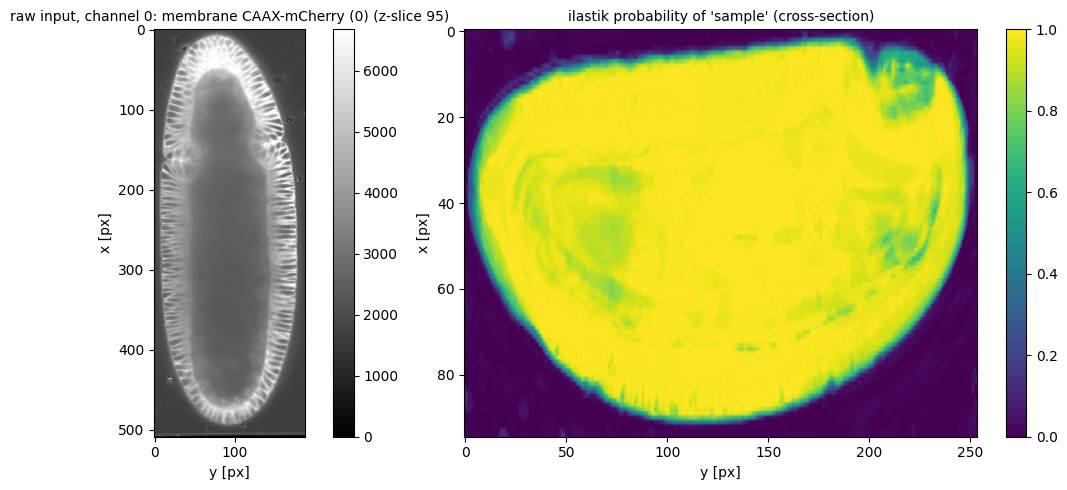

In [ ]:
z_mid = image.shape[1] // 2
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
im_ = axes[0].imshow(image[0, z_mid], cmap="gray", vmax=np.quantile(image[0, z_mid], 0.99))
axes[0].set_title(f"raw input, channel 0: {CHANNELS[0]} (z-slice {z_mid})", fontsize=10)
axes[0].set_xlabel("y [px]"); axes[0].set_ylabel("x [px]")
fig.colorbar(im_, ax=axes[0], fraction=0.046)
im_ = axes[1].imshow(segmentation[:, :, segmentation.shape[2]//2], vmin=0, vmax=1, cmap="viridis", aspect="auto")
axes[1].set_title("ilastik probability of 'sample' (cross-section)", fontsize=10)
axes[1].set_xlabel("y [px]"); axes[1].set_ylabel("x [px]")
fig.colorbar(im_, ax=axes[1], fraction=0.046)
plt.tight_layout(); plt.savefig(os.path.join(WORKDIR, "preview_inputs.png"), dpi=110); plt.show()

## Meshing: marching cubes on the probability map

Tutorial 04 cell 10: convert the segmentation into a triangular surface with `tcremesh.marching_cubes`
(libigl implementation; `sigma_smoothing=3` Gaussian smoothing, isovalue 0.5), then — per the tutorials'
"EXTREMELY IMPORTANT" convention — rescale vertex coordinates so the mesh is **in microns**, using
`resolution_in_microns / subsampling_factors` = 2.1 µm/voxel along every axis for this dataset
(the segmentation was computed on the 2×-downsampled image, consistent with its documented 2.1 µm
resolution in the add-on tutorial).

日本語: 確率画像から marching cubes で三角メッシュを生成します（チュートリアルのパラメータ通り
`isovalue=0.5, sigma_smoothing=3`）。頂点座標は必ず µm に換算します（確率画像のボクセルサイズは 2.1 µm）。

In [ ]:
vertices, faces = tcremesh.marching_cubes(segmentation, isovalue=0.5, sigma_smoothing=3)
print(f"marching cubes: {len(vertices):,} vertices, {len(faces):,} faces")

voxel_size_um = np.array(metadata_dict["resolution_in_microns"]) / np.array(metadata_dict["subsampling_factors"])
vertices_in_microns = vertices * voxel_size_um
mesh = tcmesh.ObjMesh(vertices_in_microns, faces)
print("voxel size (µm):", voxel_size_um)
print("mesh bounding box (µm):", np.round(mesh.vertices.min(0), 1), np.round(mesh.vertices.max(0), 1))

marching cubes: 81,322 vertices, 162,640 faces
voxel size (µm): [2.1 2.1 2.1]
mesh bounding box (µm): [3.2 8.1 7. ] [190.6 521.1 186.7]


## Mesh compression with libigl (tutorial 01 "Optional - mesh compression")

The marching-cubes mesh is much denser than necessary; the Python-library tutorial compresses it with
`igl.qslim` to half the face count (tutorial 01 cell 11). This is the tutorial's own step and speeds up
everything below. (Tutorial 04 instead uses the optional MeshLab remesher, which we skip.)

日本語: Python ライブラリのチュートリアル（01 セル 11）と同様に `igl.qslim` でメッシュを圧縮します
（面数を半分に）。MeshLab による再メッシュは省略しています。

In [ ]:
n_faces_before = len(mesh.faces)
vertices_remeshed, faces_remeshed, _, _ = igl.qslim(mesh.vertices, mesh.tris, max_m=int(n_faces_before / 2))
mesh = tcmesh.ObjMesh(vertices_remeshed, faces_remeshed)
print(f"qslim: {n_faces_before:,} -> {len(mesh.faces):,} faces")

qslim: 162,640 -> 81,320 faces


## Sanity check: mesh overlay on a cross-section (tutorial 04 cells 14–15)

Overlay the 3D mesh vertices on a cross-section of the raw image via the authors' helper
`tcinterp.get_cross_section_vertices_normals`, using the tutorial's parameters (slice axis 1, index 100,
width 2 µm, `origin="lower"`). If mesh and image align, the micron rescaling above is correct. (This is
a plausibility check, not a quantitative comparison.)

日本語: 著者のヘルパー関数で、メッシュ頂点（赤）を生画像の断面に重ねて描画し、
µm 換算が正しいかを確認します。

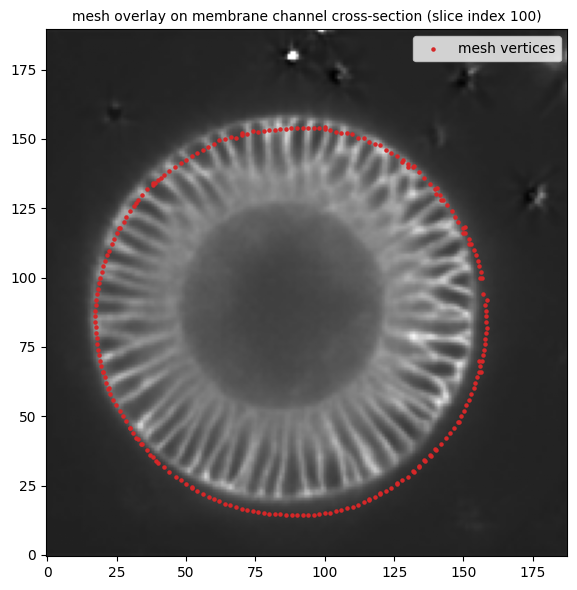

In [ ]:
slice_image, slice_vertices = tcinterp.get_cross_section_vertices_normals(
    1, 100, image, mesh, metadata_dict["resolution_in_microns"], get_normals=False, width=2)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*slice_vertices.T, s=5, c="tab:red", label="mesh vertices")
ax.imshow(slice_image[0].T, origin="lower", vmax=10000, cmap="gray")
ax.set_title("mesh overlay on membrane channel cross-section (slice index 100)", fontsize=10)
ax.legend(loc="upper right")
plt.tight_layout(); plt.savefig(os.path.join(WORKDIR, "mesh_overlay_cross_section.png"), dpi=110); plt.show()

## Automated UV mapping (replaces the interactive Blender unwrap)

In the paper/tutorial the UV map is designed interactively in Blender (seam placement + unwrap).
For a headless run we use the library's own automated UV tools instead, choosing the branch at runtime:

- **mesh with boundary (disk with holes):** the library's documented harmonic disk mapping
  `tcharmonic.map_to_disk(mesh, set_uvs=True)` (API docs: "harmonic - Harmonic mapping").
- **closed mesh (the actual case for this sample — the ilastik probability surface is topologically
  closed, unlike the hand-edited tutorial mesh):** the author's `tcharmonic.map_to_sphere` (conformal
  spherical map, `harmonic.py`) followed by a cylindrical flattening of the sphere coordinates to a 2D
  UV — **AI-generated glue**, following the authors' description of their *Drosophila* reference mesh
  as "an idealized Drosophila embryo with a cylindrical cartographic projection" (add-on tutorial,
  reference-mesh section). The u coordinate is mirrored (`u → 1−u`) to match the library's positive
  triangle-orientation convention (validated in diagnostic runs: without the mirror, ~99.6% of UV
  triangles have negative signed area).

Triangles spanning the cylindrical seam (u wrap-around) remain "flipped" by
`tcmesh.get_flipped_uv_triangles` (tutorial 01 cell 21); for them `create_cartographic_projections`
automatically uses its documented fallback interpolation (`use_fallback='auto'`), as the tutorials
themselves do for self-intersecting UV maps.

日本語: Blender での対話的 UV 展開の代わりに、ライブラリの自動 UV ツールを使います。このサンプルの
確率画像メッシュは閉じた曲面（トポロジカル的に閉じている）のため、著者の `map_to_sphere`（保角球面写像）＋
円筒展開で UV を作成します（円筒展開部分は AI が生成した補助コードで、著者の Drosophila リファレンスメッシュが
「円筒式地図投影」であることに基づきます）。円筒の継ぎ目をまたぐ三角形は自己交差として検出されますが、
著者の `create_cartographic_projections` はフォールバック補間で自動的に処理します。

In [ ]:
bnd = igl.boundary_loop(mesh.tris)
print("boundary loop length:", len(bnd), "| n_vertices:", len(mesh.vertices))
if len(bnd) > 0:
    uv_method = "harmonic map_to_disk (author function)"
    tcharmonic.map_to_disk(mesh, set_uvs=True)
else:
    import warnings
    warnings.warn("Mesh is closed: using map_to_sphere + cylindrical UV (AI-generated glue)")
    uv_method = "map_to_sphere + cylindrical UV (AI-generated glue)"
    coords_sphere = tcharmonic.map_to_sphere(mesh, set_uvs=False)
    theta = np.arctan2(coords_sphere[:, 1], coords_sphere[:, 0])       # longitude
    phi = np.arcsin(np.clip(coords_sphere[:, 2], -1, 1))               # latitude
    mesh.faces = [[[v, v] for v in fc] for fc in mesh.tris]
    # u mirrored to match the library's positive triangle-orientation convention
    mesh.texture_vertices = np.stack([(-theta) / (2*np.pi) % 1.0, phi / np.pi + 0.5], axis=1)
mesh.set_normals()
metadata_dict["uv_method"] = uv_method
print("UV method:", uv_method)
n_flipped = tcmesh.get_flipped_uv_triangles(mesh.texture_vertices, mesh.texture_tris).size
print("flipped (self-intersecting) UV triangles:", n_flipped)
metadata_dict["normal_offsets"] = np.linspace(-2, 2, 5)  # in microns, as in tutorial 04 cell 16

boundary loop length: 0 | n_vertices: 40662


/tmp/ipykernel_1458/267565042.py:8: UserWarning: Mesh is closed: using map_to_sphere + cylindrical UV (AI-generated glue)
  warnings.warn("Mesh is closed: using map_to_sphere + cylindrical UV (AI-generated glue)")


UV method: map_to_sphere + cylindrical UV (AI-generated glue)
flipped (self-intersecting) UV triangles: 283


## Cartographic projection (the paper's core operation)

`tcinterp.create_cartographic_projections` interpolates the **full-resolution 3D image** onto the UV
plane: for every point of a 512×512 UV grid (tutorial 04 cell 16) it finds the 3D surface position and
samples the image in 5 layers offset along the surface normal (`normal_offsets = -2 … +2 µm`,
tutorial 04 cells 16–17; projection resolution is independent of mesh resolution). 3D coordinates and
normals interpolated onto the UV grid are returned as well (used for the paper's distortion-corrected
analysis).

日本語: ここが論文の核心です。512×512 の UV グリッド上で、法線方向に −2〜+2 µm の 5 層オフセットを
つけながらフル解像度の 3D 画像を 2D 平面に補間します。出力形状は (1, 5, 512, 512) になるはずです。

In [ ]:
projected_data, projected_coordinates, projected_normals = tcinterp.create_cartographic_projections(
    image=os.path.join(WORKDIR, "Drosophila_CAAX-mCherry.tif"),
    mesh=mesh,
    resolution=metadata_dict["resolution_in_microns"],
    normal_offsets=metadata_dict["normal_offsets"],
    uv_grid_steps=512)
print("projected_data shape:", projected_data.shape)  # (n_channels, n_layers, 512, 512)
assert projected_data.shape == (1, 5, 512, 512), "unexpected projection shape"
print("non-NaN fraction of layer grid: %.1f%%" % (100 * np.isfinite(projected_data[:, 2]).mean()))

/usr/local/lib/python3.13/dist-packages/blender_tissue_cartography/interpolation.py:217: RuntimeWarning: UV map has self-intersections, 283 flipped triangles. Try use_fallback=True?
  warnings.warn("UV map has self-intersections, {} flipped triangles. Try use_fallback=True?".format(


projected_data shape: (1, 5, 512, 512)
non-NaN fraction of layer grid: 97.0%


## Result: the 2D cartographic projection

Display the projection of the membrane channel at **0 µm** normal offset (layer index 2) and at
**−1 µm** (layer index 1, slightly inside the tissue, as shown in tutorial 04 cell 21). This is the
paper's hallmark "cartography" view: the curved blastoderm epithelium unrolled into a planar map, in
which quantitative 2D analysis is possible. Transparent/NaN regions are parts of the UV square not
covered by the surface.

日本語: 結果です。曲がった胚上皮が 2D の「地図」に展開されています。左が表面位置（0 µm）、
右がその 1 µm 内側（チュートリアル 04 セル 21 と同じ層）です。NaN（透明）領域は UV 正方形のうち
表面が覆っていない部分です。

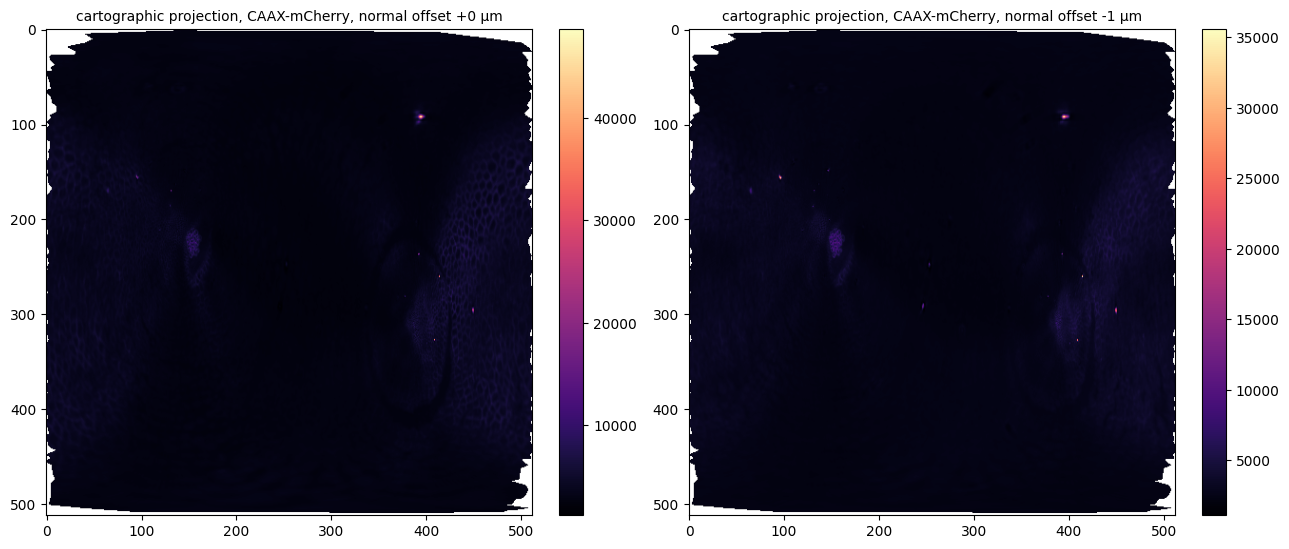

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for layer, ax in zip([2, 1], axes):
    im_ = ax.imshow(projected_data[0, layer], cmap="magma")
    offset_um = metadata_dict["normal_offsets"][layer]
    ax.set_title(f"cartographic projection, CAAX-mCherry, normal offset {offset_um:+.0f} µm", fontsize=10)
    fig.colorbar(im_, ax=ax, fraction=0.046)
plt.tight_layout(); plt.savefig(os.path.join(WORKDIR, "cartographic_projection.png"), dpi=110); plt.show()

## Save the results (tutorial cells 18–20)

Save exactly what the tutorials save: the multilayer projection as an ImageJ-compatible hyperstack
`.tif` (z = layer axis), the projected 3D coordinates and normals, the per-slice PNG texture stack for
Blender, and the metadata dictionary as JSON. A small summary table is printed from the actual run data.

日本語: チュートリアル通り、ImageJ 用 .tif（投影・座標・法線）・Blender 用テクスチャ PNG・
メタデータ JSON を保存します。

In [ ]:
import pandas as pd
tcio.save_for_imageJ(os.path.join(WORKDIR, "Drosophila_CAAX-mCherry_projected.tif"), projected_data, z_axis=1)
tcio.save_for_imageJ(os.path.join(WORKDIR, "Drosophila_CAAX-mCherry_3d_coordinates.tif"), projected_coordinates)
tcio.save_for_imageJ(os.path.join(WORKDIR, "Drosophila_CAAX-mCherry_normals.tif"), projected_normals)
texture_path = os.path.join(WORKDIR, "Drosophila_CAAX-mCherry_textures")
tcio.save_stack_for_blender(projected_data, texture_path, normalization=(0.01, 0.99))
max_projected_ch_0 = projected_data[0].max(axis=0)
tcio.imsave(f"{texture_path}/max_channel_0.png", tcio.normalize_quantiles_for_png(max_projected_ch_0))
tcio.save_dict_to_json(os.path.join(WORKDIR, "Drosophila_CAAX-mCherry_metadata.json"), metadata_dict)

summary = pd.DataFrame([
    {"quantity": "image shape (C,Z,X,Y)", "value": str(image.shape)},
    {"quantity": "resolution (z,x,y) [µm/px]", "value": str(metadata_dict["resolution_in_microns"])},
    {"quantity": "marching-cubes faces -> qslim faces", "value": f"{n_faces_before:,} -> {len(mesh.faces):,}"},
    {"quantity": "boundary loop length (0 = closed mesh)", "value": str(len(bnd))},
    {"quantity": "UV method", "value": uv_method},
    {"quantity": "flipped UV triangles", "value": str(n_flipped)},
    {"quantity": "projection shape (C, layers, U, V)", "value": str(projected_data.shape)},
    {"quantity": "normal offsets [µm]", "value": str(list(metadata_dict["normal_offsets"]))},
    {"quantity": "projection value range (layer 0 µm)",
     "value": f"[{np.nanmin(projected_data[0, 2]):.3g}, {np.nanmax(projected_data[0, 2]):.3g}]"},
])
print(summary.to_string(index=False))
print("\nwall time so far: %.1f min" % ((time.time() - t_start) / 60))
print("saved files:", sorted(os.listdir(WORKDIR)))

                              quantity                                                                                   value
                 image shape (C,Z,X,Y)                                                                      (1, 190, 509, 188)
            resolution (z,x,y) [µm/px]                                                                      (1.05, 1.05, 1.05)
   marching-cubes faces -> qslim faces                                                                       162,640 -> 81,320
boundary loop length (0 = closed mesh)                                                                                       0
                             UV method                                      map_to_sphere + cylindrical UV (AI-generated glue)
                  flipped UV triangles                                                                                     283
    projection shape (C, layers, U, V)                                                                        (

## Interpretation, validation record, and references

**What was produced:** from the shipped *Drosophila* blastoderm sample, a marching-cubes surface of the
ilastik "tissue" probability (compressed with qslim), an automated UV map, and the multilayer
cartographic projection `(1, 5, 512, 512)` of the raw image onto that map — the same quantities the
authors' tutorials report (`image (1, 190, 509, 188)`, `subsampled (1, 95, 254, 94)`,
`segmentation (95, 254, 94)`). The membrane-channel projection shows the blastoderm epithelium unrolled
into 2D, which is the paper's core capability (cf. paper Fig. 1–2).

**Validation record:** this notebook was executed top-to-bottom on a fresh Google Colab **CPU** runtime
(single example). Shapes asserted above are the tutorials' reported values; the mesh overlay is a
plausibility check of the micron scaling, not a quantitative comparison with published figures. One
example does not verify dataset-level results.

**Differences from the paper/tutorials:** (1) the interactive Blender mesh editing, seam placement and
UV unwrap are replaced by the library's automated spherical + cylindrical mapping (the shipped
probability surface is a closed mesh, so the `map_to_sphere` branch runs; the sphere→cylinder step and
the u-mirror are the labeled AI-generated glue, documented above). The few hundred UV triangles
spanning the cylindrical seam are handled by the library's documented fallback interpolation;
(2) probabilities are read from the shipped `.tif` export instead of the `.h5` (same ilastik export,
channel 0); (3) the optional MeshLab remeshing step is skipped (tutorials mark it "Optional");
(4) Blender visualization/texture viewing is omitted — the same texture PNGs are saved for it.

**References:** Development doi:10.1242/dev.205909 · bioRxiv 10.1101/2025.02.04.636523 (v3) · code
`nikolas-claussen/blender-tissue-cartography` @ `36b2471ad220ad69c6a5b140425dd19000f8d454` (Apache-2.0) · tutorials `docs/tutorials/01_btc_python_library.html` and
`docs/tutorials/04_UV_maps_with_seams.html` at that commit · sample data: Lye et al. 2024, S-BIAD1271
(via the authors' repository) · libigl (Heidelberg et al., ACM TOG). PhenoPaper investigation
`p-e537263e974a487a9b585dabfaba613e-20261030T000837Z-1859311` was used as research guidance; all steps
above were re-verified against the pinned author code.

日本語: 上記のとおり、著者チュートリアルの報告値と同じ形状がすべて確認できました。Blender での対話的な
メッシュ編集・シーム配置・UV 展開をライブラリの自動調和写像に置き換えた点、確率画像を .h5 ではなく .tif から
読む点、MeshLab 再メッシュを省略した点が元手順との違いです。単一サンプルの実行であり、論文の
データセット規模の結果の検証ではありません。